# Notebook 03 - DDS, Pembentukan Dataset, Split, dan Analisis Fitur

Notebook ini membentuk dataset penelitian. LIN/PBN diparse, DDS v4 menetapkan label biner, lalu satu proses deduplikasi dan split deal-aware menulis dua keluaran: dataset dengan DDS dan dataset noDDS. Keduanya memakai board, label, urutan, dan partisi yang sama. Bagian akhir notebook menganalisis 164 fitur noDDS pada train set.


## 0. Setup


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

_root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _root_candidates if (p / "configs" / "config.yaml").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Tidak menemukan root repo (configs/config.yaml dan src/). Jalankan notebook dari repo atau folder notebooks.")
sys.path.insert(0, str(ROOT))
OUT = ROOT / 'outputs' / 'results'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})
sns.set_theme(style='whitegrid', palette='colorblind')
print(f'Repo: {ROOT}')

Repo: d:\Bridge-Prediction


## 1. DDS untuk Label, Dua Dataset, dan Split Deal-Aware

DDS menentukan apakah kontrak aktual cocok dengan salah satu kontrak par berdasarkan level, strain, status double/redouble, dan sisi declarer. Label `matches_par_contract` dipertahankan dalam kedua keluaran.

Dalam satu pemanggilan builder, record dideduplikasi dan dibagi berdasarkan tanda tangan deal 52 kartu. Builder kemudian menulis dua dataset:

- `data/processed/`: 174 fitur (164 fitur kanonik + 10 fitur jumlah trik DDS).
- `data/processed_no_dds/`: 164 fitur kanonik tanpa kolom trik atau rincian par DDS.

DDS tetap diperlukan untuk membentuk label, tetapi nilai DDS tidak diberikan sebagai input model noDDS.


In [2]:
import json
from src.parser import PBNParser
from src.preprocessing import build_dataset

RAW_DIR = ROOT / "data" / "raw"
PBN_DIR = ROOT / "data" / "raw_pbn"
DDS_CACHE = ROOT / "data" / "combined_dds_cache_v4.csv"
DDS_DIR = ROOT / "data" / "processed"
NO_DDS_DIR = ROOT / "data" / "processed_no_dds"
FORCE_REBUILD = False  # set True setelah data sumber/definisi pipeline berubah

if not DDS_CACHE.exists():
    raise FileNotFoundError(f"Cache DDS v4 tidak ditemukan: {DDS_CACHE}")

required_files = [
    *[folder / f"{part}.csv" for folder in (DDS_DIR, NO_DDS_DIR) for part in ("full", "train", "val", "test")],
    DDS_DIR / "feature_columns.json", NO_DDS_DIR / "feature_columns.json",
    DDS_DIR / "label_encoder.pkl", NO_DDS_DIR / "label_encoder.pkl",
]
needs_build = FORCE_REBUILD or not all(path.exists() for path in required_files)
key_types = {"_source_file": str, "_room": str, "_board_number": str, "_deal_key": str}

if needs_build:
    if FORCE_REBUILD:
        for folder in (DDS_DIR, NO_DDS_DIR):
            folder.mkdir(parents=True, exist_ok=True)
            for pattern in ("*.csv", "*.pkl", "*.json"):
                for old_file in folder.glob(pattern):
                    old_file.unlink()
    pbn_boards = PBNParser().parse_directory(PBN_DIR)
    print(f"Membangun dataset dari LIN + {len(pbn_boards):,} board PBN")
    splits = build_dataset(
        raw_dir=RAW_DIR,
        output_dir=DDS_DIR,
        no_dds_output_dir=NO_DDS_DIR,
        target_col="matches_par_contract",
        train_ratio=0.70,
        val_ratio=0.15,
        test_ratio=0.15,
        random_seed=42,
        include_dds=True,
        dds_cache_path=DDS_CACHE,
        extra_boards=pbn_boards,
    )
    full_dds = splits["full"]
    full_no_dds = pd.read_csv(NO_DDS_DIR / "full.csv", keep_default_na=False, dtype=key_types)
else:
    print("Dataset DDS dan noDDS sudah tersedia; tidak membangun ulang.")
    full_dds = pd.read_csv(DDS_DIR / "full.csv", keep_default_na=False, dtype=key_types)
    full_no_dds = pd.read_csv(NO_DDS_DIR / "full.csv", keep_default_na=False, dtype=key_types)

features_dds = json.loads((DDS_DIR / "feature_columns.json").read_text(encoding="utf-8"))
features_no_dds = json.loads((NO_DDS_DIR / "feature_columns.json").read_text(encoding="utf-8"))
identity_label = ["_source_file", "_room", "_board_number", "_deal_key", "label", "matches_par_contract"]
assert len(features_dds) == 174 and len(features_no_dds) == 164
assert full_dds[identity_label].equals(full_no_dds[identity_label])
assert features_no_dds == [c for c in features_dds if not c.startswith(("ns_dd_", "ew_dd_", "dd_par_"))]
assert not any(c.startswith(("ns_dd_", "ew_dd_", "dd_par_")) for c in full_no_dds.columns)

for part in ("train", "val", "test"):
    dds_part = pd.read_csv(DDS_DIR / f"{part}.csv", usecols=identity_label, dtype=key_types, keep_default_na=False, low_memory=False)
    no_dds_part = pd.read_csv(NO_DDS_DIR / f"{part}.csv", usecols=identity_label, dtype=key_types, keep_default_na=False, low_memory=False)
    assert dds_part.equals(no_dds_part), f"Identitas, label, atau split berbeda pada {part}"

print(f"Board: {len(full_dds):,} | positif: {full_dds['matches_par_contract'].mean():.2%}")
print(f"Fitur DDS: {len(features_dds)} | fitur noDDS: {len(features_no_dds)}")
print("Label dan pembagian board identik untuk train, validation, dan test.")

Dataset DDS dan noDDS sudah tersedia; tidak membangun ulang.
Board: 50,227 | positif: 24.56%
Fitur DDS: 174 | fitur noDDS: 164
Label dan pembagian board identik untuk train, validation, dan test.


## 2. Profil Dataset noDDS (Train Set)

Muat split resmi, lalu gunakan train set untuk ringkasan fitur dan hubungan dengan target. Dataset, label, dan pembagian split tidak diubah.


In [3]:
import json

NO_DDS_DIR = ROOT / 'data' / 'processed_no_dds'
key_types = {"_source_file": str, "_room": str, "_board_number": str, "_deal_key": str}
df = pd.read_csv(
    NO_DDS_DIR / 'train.csv',
    keep_default_na=False,
    dtype=key_types,
    low_memory=False,
)
feature_cols = json.loads((NO_DDS_DIR / 'feature_columns.json').read_text(encoding='utf-8'))
target_col = 'matches_par_contract'
assert target_col in df.columns, f'Target tidak ditemukan: {target_col}'
assert len(feature_cols) == 164, f'Diharapkan 164 fitur, ditemukan {len(feature_cols)}'
assert not any(col.startswith(('ns_dd_', 'ew_dd_', 'dd_par_')) for col in feature_cols), 'Fitur DDS/par DDS tidak boleh masuk model noDDS.'

class_names = {0: 'Tidak cocok par', 1: 'Cocok par'}
df['target_name'] = df[target_col].map(class_names)
print(f'Train set: {len(df):,} baris | {len(feature_cols)} fitur noDDS')
print(f'Positif train: {df[target_col].mean():.1%}')
print('Analisis fitur dibatasi ke train set; validation dan test tidak dibaca di notebook ini.')


Train set: 35,161 baris | 164 fitur noDDS
Positif train: 24.6%
Analisis fitur dibatasi ke train set; validation dan test tidak dibaca di notebook ini.


## 3. Inventaris kelompok fitur

Kelompok berikut merangkum isi 164 kolom input. Kolom par DDS yang membentuk label tidak termasuk dalam fitur model.


In [4]:
def group_features(cols):
    return {
        'Tangan per seat': [c for c in cols if c.startswith(('N_', 'E_', 'S_', 'W_'))],
        'Kemitraan': [c for c in cols if c.startswith(('ns_', 'ew_')) and 'advantage' not in c],
        'Keunggulan HCP': [c for c in cols if 'advantage' in c],
        'Dealer dan vulnerability': [c for c in cols if c.startswith(('dealer_', 'vuln_'))],
        'Auction': [c for c in cols if c.startswith(('auction_', 'opening_'))],
    }

groups = group_features(feature_cols)
assigned = [col for cols in groups.values() for col in cols]
assert len(assigned) == len(set(assigned)) == len(feature_cols), 'Kelompok fitur tumpang tindih atau tidak mencakup semua fitur.'
summary = pd.DataFrame({'Kelompok': groups.keys(), 'Jumlah fitur': [len(v) for v in groups.values()]})
display(summary)
print(f'Total fitur: {summary["Jumlah fitur"].sum()}')

,Kelompok,Jumlah fitur
0,Tangan per seat,96
1,Kemitraan,44
2,Keunggulan HCP,1
3,Dealer dan vulnerability,8
4,Auction,15


Total fitur: 164


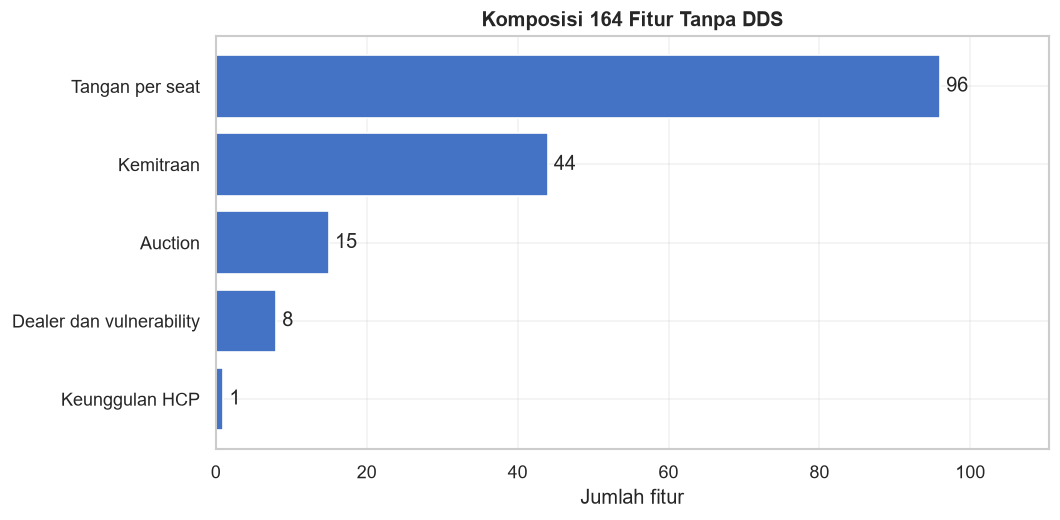

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_groups = summary.sort_values('Jumlah fitur')
ax.barh(plot_groups['Kelompok'], plot_groups['Jumlah fitur'], color='#4472C4')
for y, value in enumerate(plot_groups['Jumlah fitur']):
    ax.text(value + 0.8, y, str(value), va='center')
ax.set_xlim(0, plot_groups['Jumlah fitur'].max() * 1.15)
ax.set_xlabel('Jumlah fitur')
ax.set_title('Komposisi 164 Fitur Tanpa DDS', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb03_feature_groups.png', bbox_inches='tight')
plt.show()

## 4. HCP dan kekuatan kemitraan menurut target

Bandingkan HCP NS, HCP EW, dan selisih HCP NS-EW antara board yang kontrak aktualnya cocok dan tidak cocok dengan par.


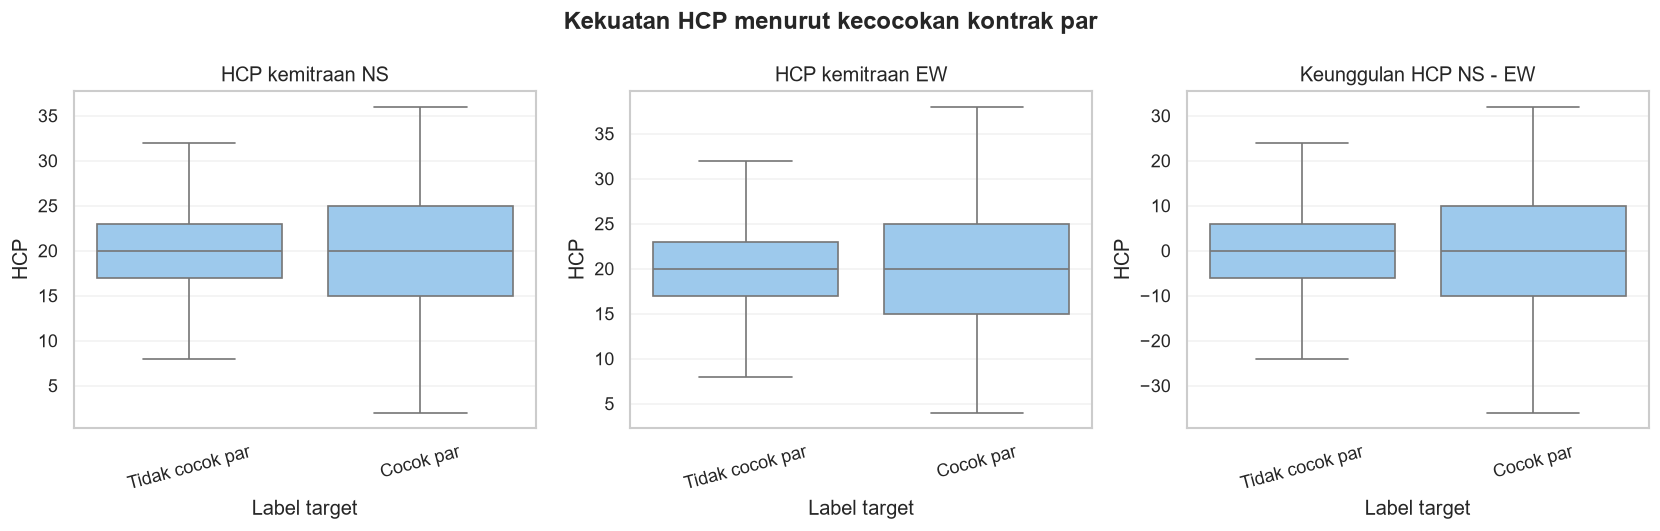

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col, title in zip(
    axes,
    ['ns_hcp', 'ew_hcp', 'ns_hcp_advantage'],
    ['HCP kemitraan NS', 'HCP kemitraan EW', 'Keunggulan HCP NS - EW'],
):
    sns.boxplot(data=df, x='target_name', y=col, order=['Tidak cocok par', 'Cocok par'],
                showfliers=False, ax=ax, color='#90CAF9')
    ax.set_title(title)
    ax.set_xlabel('Label target')
    ax.set_ylabel('HCP')
    ax.tick_params(axis='x', rotation=15)
plt.suptitle('Kekuatan HCP menurut kecocokan kontrak par', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb03_hcp_by_target.png', bbox_inches='tight')
plt.show()

## 5. Fit, stopper, dan Losing Trick Count

Ringkas beberapa fitur kemitraan yang menggambarkan dukungan suit, stopper NT, dan kualitas tangan. Perbedaan antarkelompok target bersifat deskriptif.


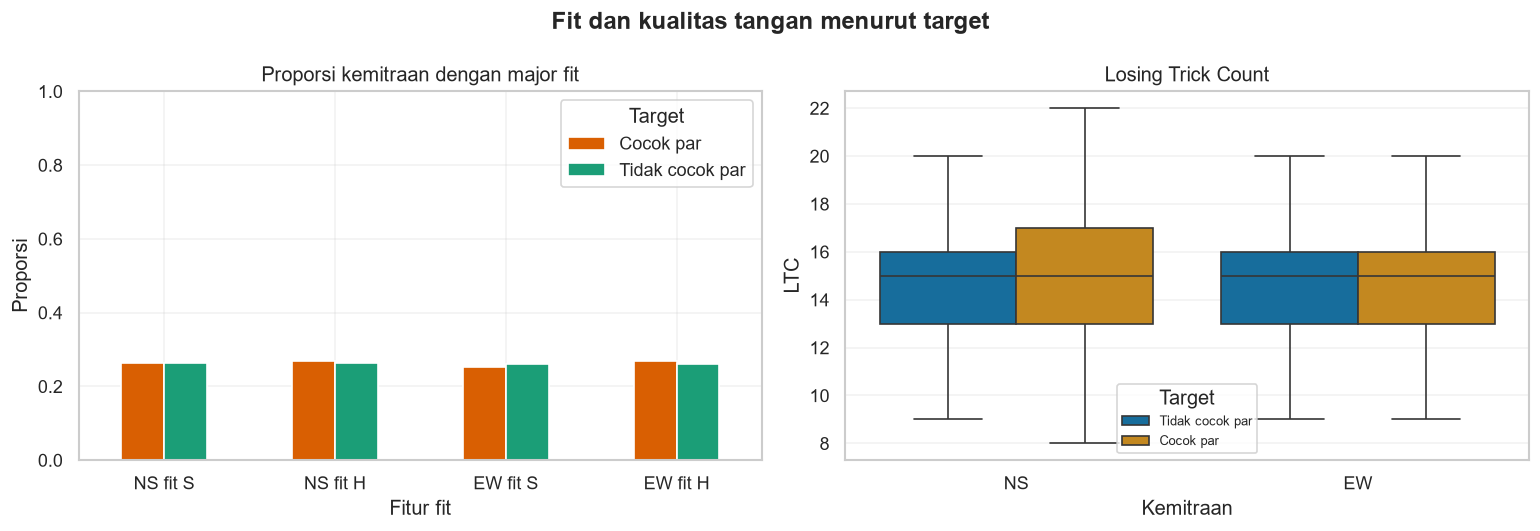

In [7]:
fit_cols = ['ns_has_fit_S', 'ns_has_fit_H', 'ew_has_fit_S', 'ew_has_fit_H']
fit_rates = df.groupby('target_name')[fit_cols].mean().T
fit_rates.index = ['NS fit S', 'NS fit H', 'EW fit S', 'EW fit H']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fit_rates.plot(kind='bar', ax=axes[0], color=['#D95F02', '#1B9E77'])
axes[0].set_title('Proporsi kemitraan dengan major fit')
axes[0].set_xlabel('Fitur fit')
axes[0].set_ylabel('Proporsi')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Target')

ltc = df[['ns_ltc', 'ew_ltc', 'target_name']].melt(id_vars='target_name', var_name='fitur', value_name='LTC')
ltc['Kemitraan'] = ltc['fitur'].map({'ns_ltc': 'NS', 'ew_ltc': 'EW'})
sns.boxplot(data=ltc, x='Kemitraan', y='LTC', hue='target_name',
            hue_order=['Tidak cocok par', 'Cocok par'], showfliers=False, ax=axes[1])
axes[1].set_title('Losing Trick Count')
axes[1].set_xlabel('Kemitraan')
axes[1].set_ylabel('LTC')
axes[1].legend(title='Target', fontsize=8)
plt.suptitle('Fit dan kualitas tangan menurut target', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb03_fit_ltc_by_target.png', bbox_inches='tight')
plt.show()

## 6. Fitur auction menurut target

Tampilkan panjang auction dan proporsi auction kompetitif untuk dua kelas target.


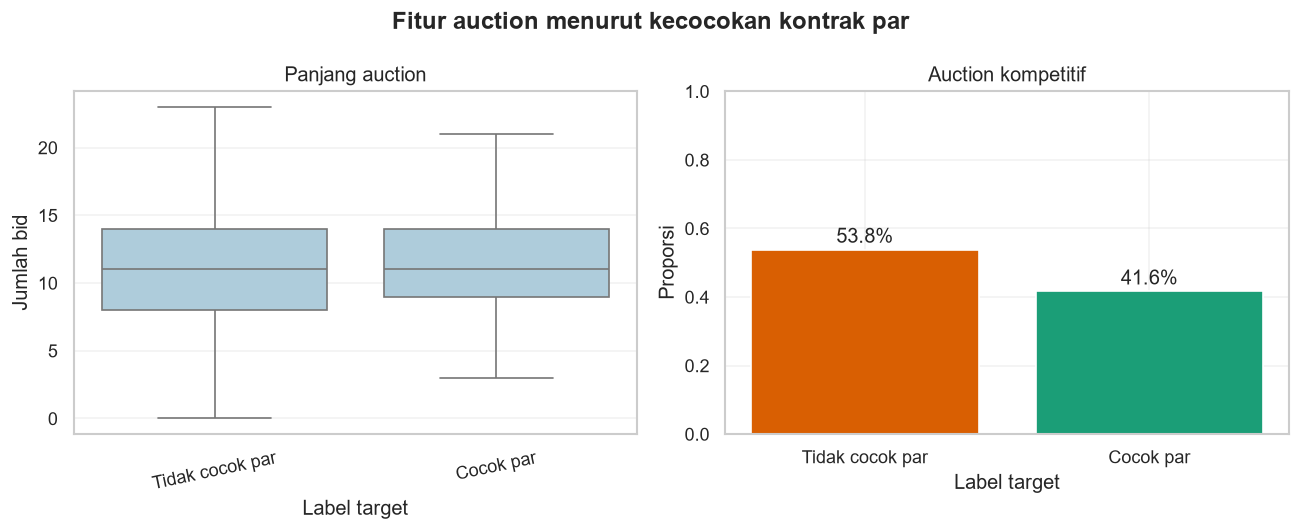

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=df, x='target_name', y='auction_len',
            order=['Tidak cocok par', 'Cocok par'], showfliers=False, ax=axes[0], color='#A6CEE3')
axes[0].set_title('Panjang auction')
axes[0].set_xlabel('Label target')
axes[0].set_ylabel('Jumlah bid')
axes[0].tick_params(axis='x', rotation=12)

competitive = df.groupby('target_name')['auction_competitive'].mean().reindex(['Tidak cocok par', 'Cocok par'])
axes[1].bar(competitive.index, competitive.values, color=['#D95F02', '#1B9E77'])
axes[1].set_title('Auction kompetitif')
axes[1].set_xlabel('Label target')
axes[1].set_ylabel('Proporsi')
axes[1].set_ylim(0, 1)
for i, value in enumerate(competitive.values):
    axes[1].text(i, value + 0.02, f'{value:.1%}', ha='center')
plt.suptitle('Fitur auction menurut kecocokan kontrak par', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb03_auction_by_target.png', bbox_inches='tight')
plt.show()

## 7. Pemeriksaan asosiasi fitur dan leakage

Urutkan asosiasi Pearson fitur numerik dengan target biner sebagai pemeriksaan univariat sederhana. Ini **bukan** feature importance dan tidak menangkap hubungan non-linear. Kolom `dd_par_*` tidak boleh muncul dalam daftar input karena kolom par membentuk label.


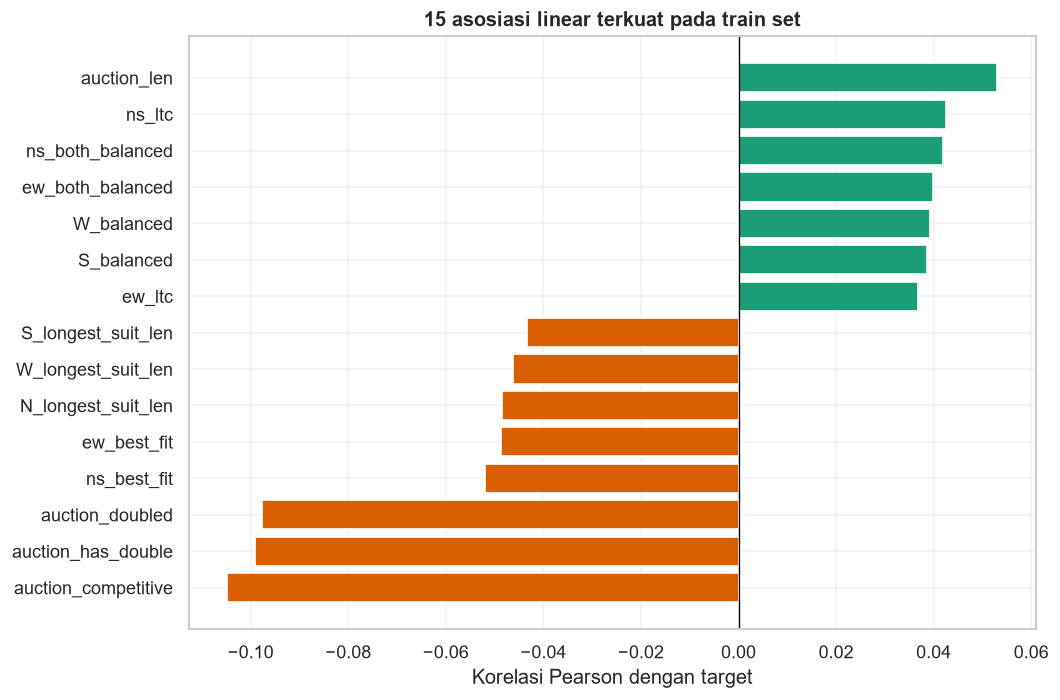

Kolom par DDS dalam fitur model: []
Korelasi hanya ringkasan univariat; gunakan evaluasi model/SHAP untuk analisis prediksi.


In [9]:
X = df[feature_cols].select_dtypes(include='number')
y = df[target_col].astype(float)
correlations = X.corrwith(y).dropna()
top_corr = correlations.reindex(correlations.abs().sort_values(ascending=False).head(15).index).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#D95F02' if value < 0 else '#1B9E77' for value in top_corr.values]
ax.barh(top_corr.index, top_corr.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Korelasi Pearson dengan target')
ax.set_title('15 asosiasi linear terkuat pada train set', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'nb03_feature_target_association.png', bbox_inches='tight')
plt.show()
print('Kolom par DDS dalam fitur model:', [c for c in feature_cols if c.startswith('dd_par_')])
print('Korelasi hanya ringkasan univariat; gunakan evaluasi model/SHAP untuk analisis prediksi.')

## Ringkasan dan langkah berikutnya

Bagian ini adalah profil data pendukung pada train set untuk memahami dataset sebelum pemodelan. Ringkasan komposisi fitur serta perbandingan HCP, fit/LTC, dan auction bersifat deskriptif; bagian ini bukan analisis hasil model dan tidak mengubah fitur, split, atau pemilihan model.

**Urutan berikutnya:** Notebook 04 melatih baseline pada dataset 164 fitur tanpa DDS.
